In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def make_image_grid_matplotlib(root_dir, labels, ids, cell_size=(3.2, 3.2), style='cyberpunk'):
    """
    Rows = ids, columns = labels.
    Expects: {root_dir}/{label}00_0.000/{id}.png
    """
    labels = [str(l) for l in labels]
    nrows, ncols = len(ids), len(labels)
    figsize = (cell_size[0] * ncols, cell_size[1] * nrows)

    # Zero spacing between subplots
    fig, axes = plt.subplots(
        nrows, ncols, figsize=figsize,
        gridspec_kw={"wspace": 0.0, "hspace": 0.0}
    )

    # Ensure axes is always 2D
    if nrows == 1 and ncols == 1:
        axes = axes.reshape(1, 1)
    elif nrows == 1:
        axes = axes.reshape(1, -1)
    elif ncols == 1:
        axes = axes.reshape(-1, 1)

    for r, id_ in enumerate(ids):
        for c, lab in enumerate(labels):
            ax = axes[r, c]
            path = os.path.join(root_dir, f"{lab}00_0.000", f"{id_}.png")
            img = mpimg.imread(path)
            ax.imshow(img)
            ax.axis("off")  # no ticks/borders
            # bottom-left label box
            ax.text(
                6, img.shape[0] - 10, lab,
                color="white", fontsize=12, fontweight="bold",
                bbox=dict(facecolor="black", alpha=0.6, pad=3)
            )

    # Remove outer figure margins
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

    # IMPORTANT: do NOT call tight_layout(); it reintroduces padding.
    out_base = f"style_visualize_{style}"
    fig.savefig(f"{out_base}.pdf", dpi=200, bbox_inches="tight", pad_inches=0)
    fig.savefig(f"{out_base}.png", dpi=50, bbox_inches=0, pad_inches=0)
    return fig, axes


In [3]:
model = "FLUX.1-schnell"

(<Figure size 1600x2240 with 35 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

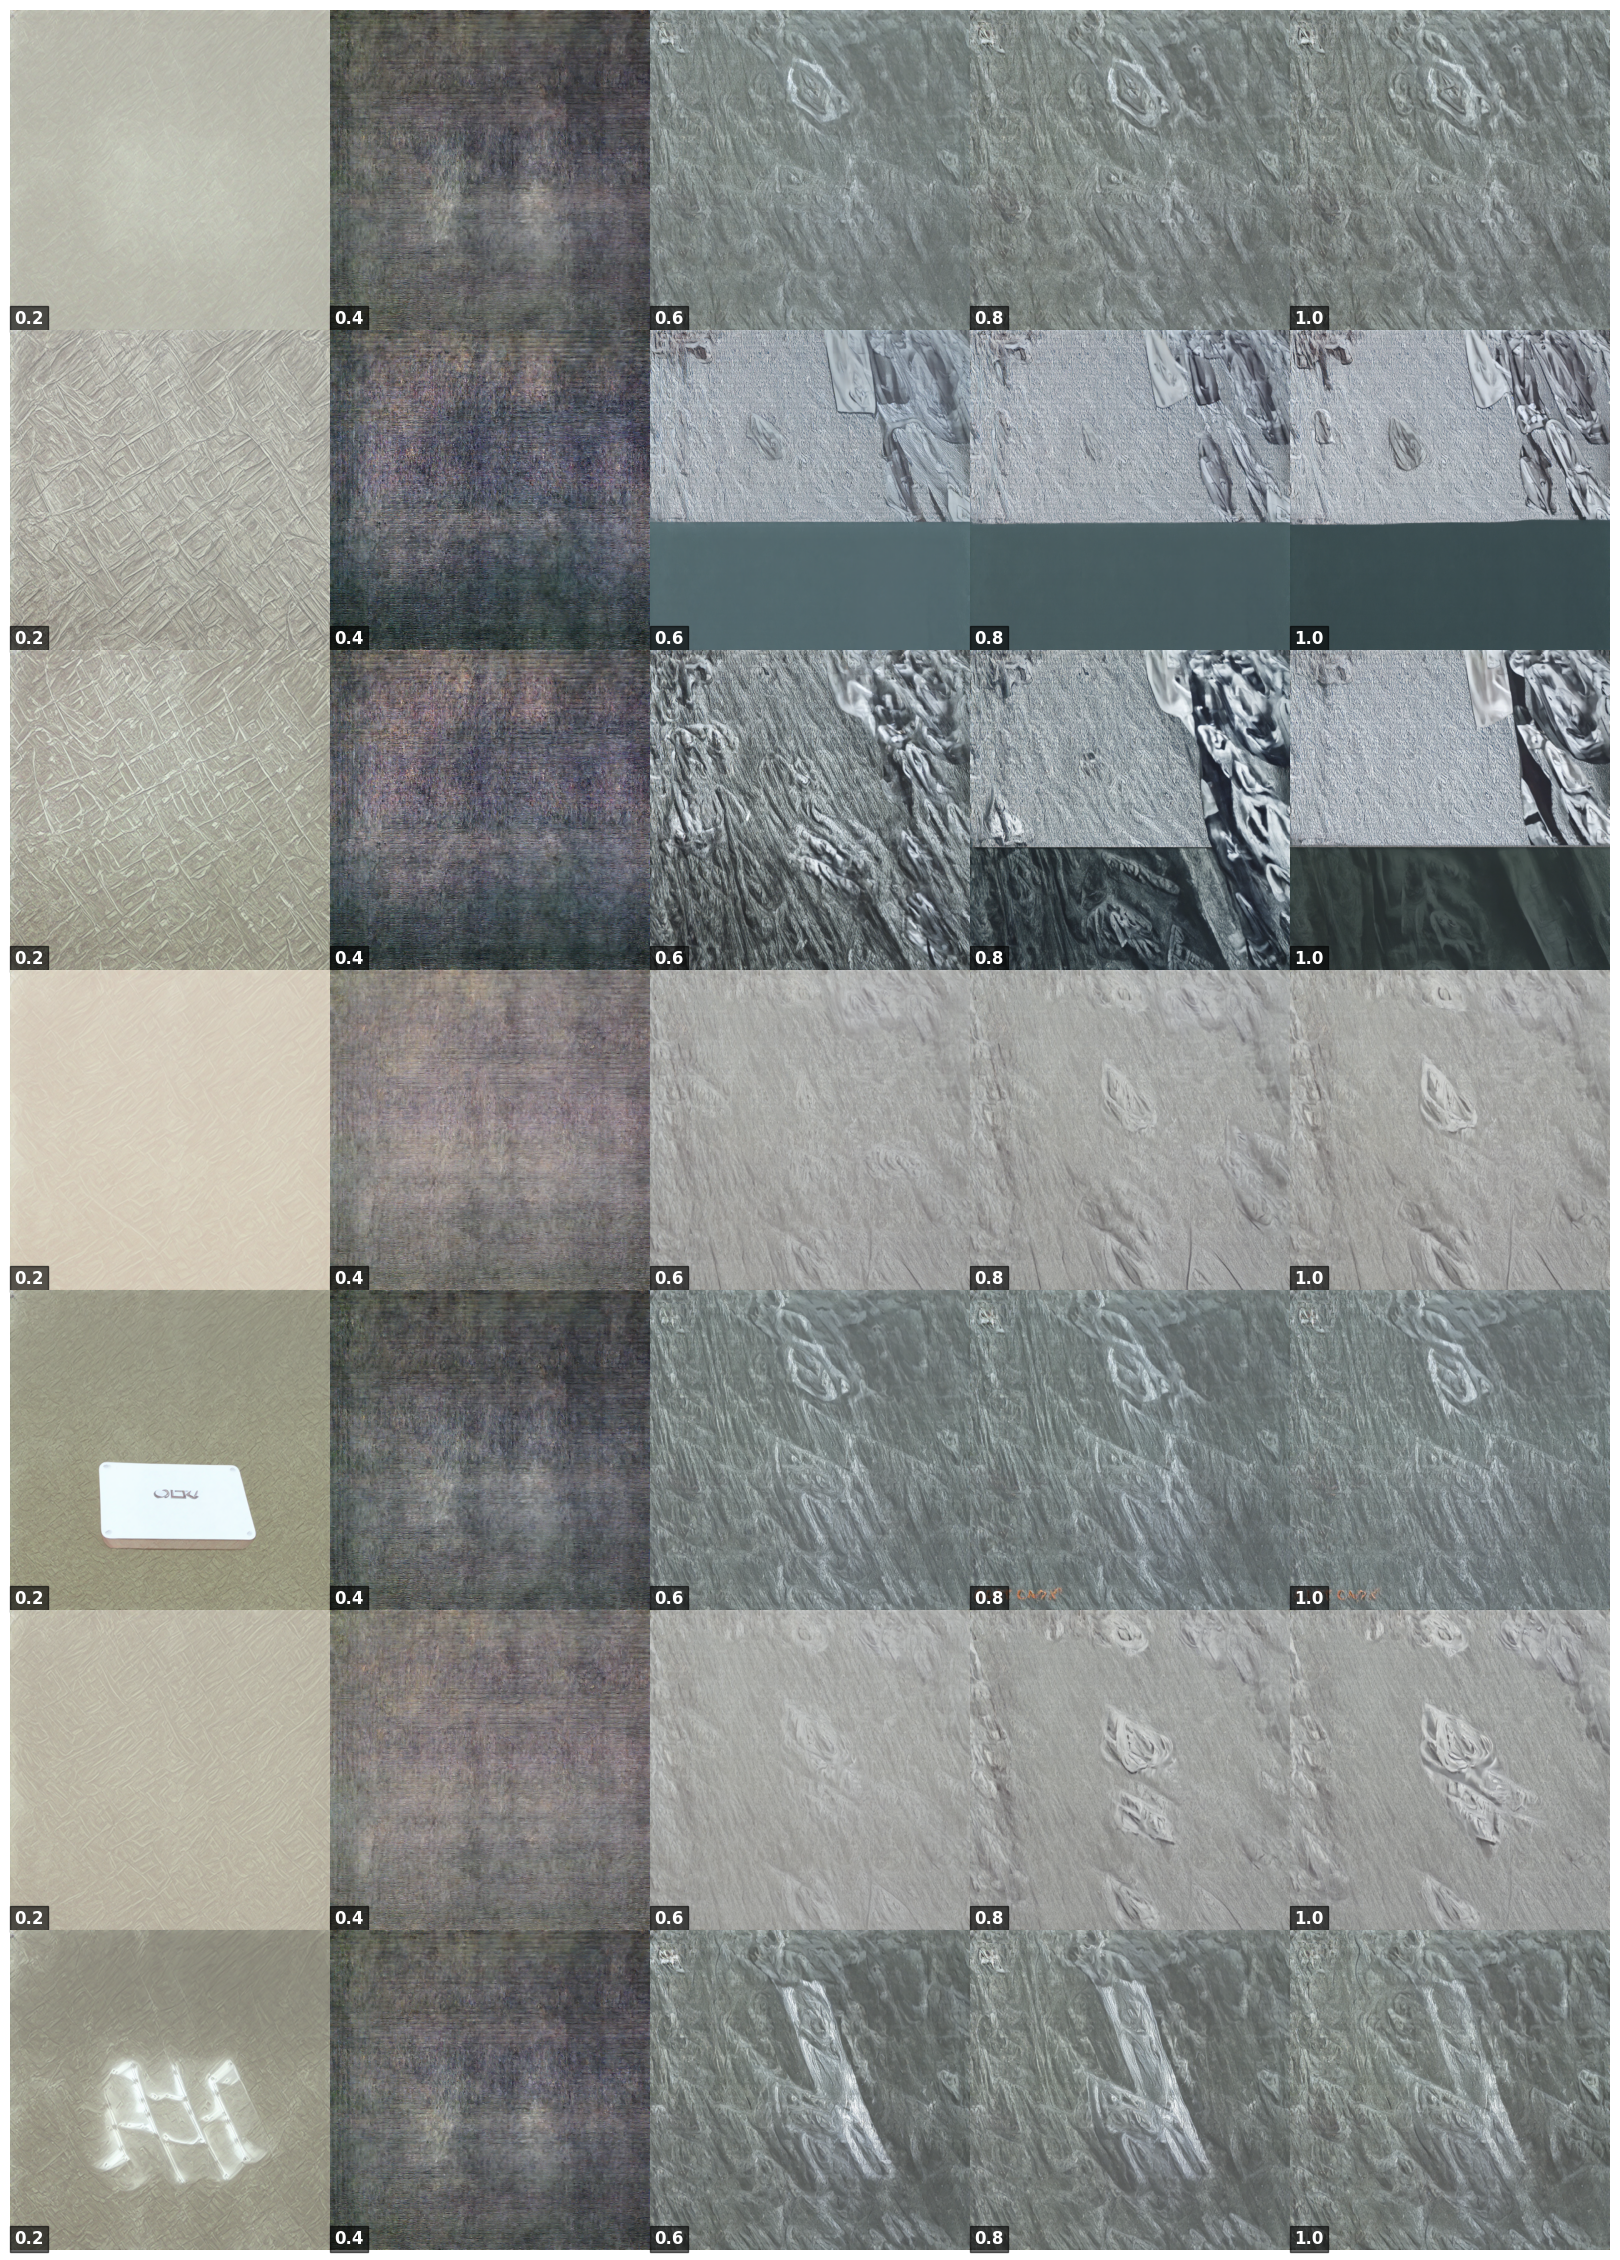

In [ ]:
style = 'cyberpunk'
img_path = f"results_{model}_linear_ot_{style}_38/generate_with_hooks_diffusion/coco-captions-styles/none%3Acyberpunk/incr-linear_ot-mean/transfor..cks.11%3A0"
labels = [0.2,0.4,0.6,0.8,1.0]
img_ids = ['101203', '784562', '503832', '65302', '443957', '472409', '509247']

make_image_grid_matplotlib(root_dir=img_path, labels=labels, ids=img_ids, style=style)

In [ ]:
style = 'gothic'
img_path = f"results_{style}_42/generate_with_hooks_diffusion/coco-captions-styles/none:{style}/incr-mean_ot-mean/transfor..cks.11:0"
labels = [0.2,0.4,0.6,0.8,1.0]
img_ids = ['101203', '784562', '503832', '65302', '443957', '472409', '509247']

make_image_grid_matplotlib(root_dir=img_path, labels=labels, ids=img_ids, style=style)